# Notebook 04 — LSTM BTC15m YES: walk-forward + Monte Carlo Dropout

Compara **baseline determinista** contra **filtro de incertidumbre MC Dropout** en los mismos folds mensuales (mayo–octubre 2026). Se conserva el objetivo **long-only YES**, las tres ablaciones de variables, el entrenamiento expansivo, la validación temporal y la regla de **máximo una compra por contrato**.

**Regla MC:** comprar solo cuando el **límite inferior** de un intervalo central de las probabilidades de YES estimadas con Dropout supera `ask + costos + edge mínimo`. Los niveles de intervalo (80%, 90%, 95%, 99%), el edge y la ventana temporal se seleccionan **solo con validation**, por separado para baseline y MC. Se incluyen variantes con igual política económica y se informa cobertura, número de operaciones y PnL acumulado.

**Advertencia:** el intervalo de MC Dropout describe dispersión de predicciones bajo máscaras de dropout; **no es un intervalo de confianza frecuentista calibrado** para la verdadera probabilidad. Las cotizaciones históricas pueden ser proxies no ejecutables; el PnL no incluye tarifas reales ni verificación de liquidez.


Se comparan dos conjuntos de variables: A (BRTI) y B (BRTI + Kalshi). No se utiliza información de otros mercados.

El backtest usa el ask de la vela recién cerrada como aproximación de entrada, sin esperar un minuto adicional. No es una confirmación de ejecución.

Para comparar A y B sobre las mismas decisiones se exige bid/ask y spread válidos en ambos modelos, aunque A no utilice esos precios como predictores.

In [1]:
# %pip install torch scikit-learn pandas numpy matplotlib pyarrow
from pathlib import Path
import json, random, copy, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn.utils.rnn import pack_padded_sequence
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import log_loss, brier_score_loss, roc_auc_score, accuracy_score
from IPython.display import display

SEED=1234
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic=True
torch.backends.cudnn.benchmark=False
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
ROOT=Path('data/processed')
BASE_OUT=Path('data/modeling')
OUT=BASE_OUT/'lstm'; OUT.mkdir(parents=True,exist_ok=True)
DATA_PATH=next((p for p in [ROOT/'dataset_completo.parquet',ROOT/'dataset_completo.csv',
    Path('dataset_completo.parquet'),Path('dataset_completo.csv')] if p.exists()),None)
assert DATA_PATH is not None, 'Falta dataset_completo: ejecutar notebook 02.'
MIN_KALSHI_AGE=0
EMBARGO_SECONDS=900
SEQ_LEN=10                 # máximo de observaciones históricas del mismo contrato
BATCH_SIZE=256
EPOCHS=60
PATIENCE=8
MIN_TRADES_VALIDATION=20
FEE_PER_SIDE=0.0           # costo hipotético por contrato al comprar YES
SLIPPAGE_PER_SIDE=0.0      # costo hipotético adicional
MIN_EDGE_THRESHOLDS=[0.01,0.02,0.03,0.05,0.08,0.10]
# (mínimo, máximo) de minutos restantes al vencimiento, inclusive.
TIME_WINDOWS = [(1, 14), (1, 5), (3, 7), (5, 10), (7, 14), (3, 10)]
# Configuraciones acotadas para controlar sobreajuste. Solo validation selecciona.
PARAM_GRID=[
    dict(hidden_dim=32,num_layers=1,dropout=0.10,lr=1e-3,weight_decay=1e-4),
    dict(hidden_dim=64,num_layers=1,dropout=0.20,lr=5e-4,weight_decay=1e-3),
    dict(hidden_dim=64,num_layers=2,dropout=0.2,lr=5e-4,weight_decay=1e-3),
]
df=pd.read_parquet(DATA_PATH) if DATA_PATH.suffix=='.parquet' else pd.read_csv(DATA_PATH)
print('Datos:',DATA_PATH,'| device:',DEVICE,'| filas:',len(df))

# MC Dropout: 100 realizaciones por decisión (subir a 200-500 para percentiles 99% más estables).
MC_SAMPLES=100
MC_CONFIDENCE_LEVELS=[0.80,0.90,0.95,0.99]
MC_SEED_OFFSET=90000


Datos: data/processed/dataset_completo.parquet | device: cpu | filas: 423135


In [2]:

# Fold mensual: entrenamiento expansivo, validación del mes anterior,
# test del mes actual. Se exigen 4 meses completos iniciales de train.
INITIAL_TRAIN_MONTHS = 4
VALIDATION_MONTHS = 1
TEST_MONTHS = 1
START_TEST_MONTH = "2026-05"
END_TEST_MONTH = "2026-10"
EMBARGO_SECONDS = 900

def prepare_data(df):
    # Dos grupos de variables: subyacente solamente, y subyacente + Kalshi.
    brti = ['minutes_remaining', 'brti_distance_to_strike_pct',
            'brti_return_1m', 'ewma_volatility_bps_min']
    kalshi = brti + ['kalshi_yes_price_proxy', 'kalshi_spread']
    features = {'A_BRTI': brti, 'B_BRTI_Kalshi': kalshi}

    required = ['ticker', 'decision_ts', 'contract_start_ts', 'contract_close_ts',
                'target_yes', 'valid_for_training', 'kalshi_feature_candle_end_ts',
                'kalshi_yes_bid', 'kalshi_yes_ask'] + kalshi
    missing = sorted(set(required) - set(df.columns))
    assert not missing, f'Faltan columnas: {missing}'
    base = df.copy()
    for column in set(required) - {'ticker', 'valid_for_training'}:
        base[column] = pd.to_numeric(base[column], errors='coerce')
    if base.valid_for_training.dtype != bool:
        base['valid_for_training'] = base.valid_for_training.astype(str).str.lower().isin(['true', '1'])

    assert not base.duplicated(['ticker', 'decision_ts']).any()
    assert base.groupby('ticker').contract_start_ts.nunique().max() == 1
    assert base.groupby('ticker').target_yes.nunique().max() == 1
    base = base.loc[
        base.valid_for_training &
        base.target_yes.isin([0, 1]) &
        base.minutes_remaining.gt(0) &
        base.decision_ts.ge(base.contract_start_ts) &
        base.decision_ts.lt(base.contract_close_ts) &
        base.kalshi_feature_candle_end_ts.eq(base.decision_ts)
    ].copy()
    base = base.replace([np.inf, -np.inf], np.nan).dropna(subset=kalshi)
    base = base.loc[
        base.kalshi_yes_bid.between(0, 1) &
        base.kalshi_yes_ask.between(0, 1) &
        base.kalshi_yes_bid.le(base.kalshi_yes_ask)
    ]
    base = base.sort_values(['contract_start_ts', 'ticker', 'decision_ts']).reset_index(drop=True)
    assert not base.empty, 'No quedaron observaciones válidas para entrenar.'
    return base, features

def monthly_folds(base):
    # UTC month boundaries, independent of arbitrary row percentages.
    contract=base[['ticker','contract_start_ts','contract_close_ts']].drop_duplicates('ticker')
    assert contract.ticker.is_unique
    months=pd.period_range(START_TEST_MONTH,END_TEST_MONTH,freq='M')
    for month in months:
        test_start=pd.Timestamp(month.start_time,tz='UTC').timestamp()
        test_end=pd.Timestamp((month+1).start_time,tz='UTC').timestamp()
        val_start=pd.Timestamp((month-VALIDATION_MONTHS).start_time,tz='UTC').timestamp()
        train_start=pd.Timestamp((pd.Period(START_TEST_MONTH,freq='M')-VALIDATION_MONTHS-INITIAL_TRAIN_MONTHS).start_time,tz='UTC').timestamp()
        # No contrato que cierra en / después de frontera puede entrar en el bloque previo.
        train_ids=contract.loc[(contract.contract_start_ts>=train_start)&
            (contract.contract_close_ts<=val_start-EMBARGO_SECONDS),'ticker']
        val_ids=contract.loc[(contract.contract_start_ts>=val_start+EMBARGO_SECONDS)&
            (contract.contract_close_ts<=test_start-EMBARGO_SECONDS),'ticker']
        test_ids=contract.loc[(contract.contract_start_ts>=test_start+EMBARGO_SECONDS)&
            (contract.contract_close_ts<=test_end),'ticker']
        parts={k:base.loc[base.ticker.isin(ids)].sort_values(
            ['ticker','decision_ts'],kind='stable').reset_index(drop=True)
            for k,ids in [('train',train_ids),('validation',val_ids),('test',test_ids)]}
        assert all(set(parts[a].ticker).isdisjoint(parts[b].ticker)
                   for a,b in [('train','validation'),('train','test'),('validation','test')])
        for k,p in parts.items():
            assert not p.empty, f"Fold {month}: {k} vacío; verificar cobertura histórica"
            assert p.target_yes.nunique()==2, f"Fold {month}: {k} sin ambas clases"
        yield str(month),parts

def weights_by_contract(d):
    w=1/d.groupby('ticker').ticker.transform('size').to_numpy(dtype=float)
    return w/w.mean()

def metric_row(model,month,part,prob):
    y=part.target_yes.astype(int).to_numpy()
    p=np.clip(np.asarray(prob),1e-7,1-1e-7)
    w=weights_by_contract(part)
    return dict(model=model,fold=month,rows=len(part),contracts=part.ticker.nunique(),
        logloss=log_loss(y,p,labels=[0,1]),
        weighted_logloss=log_loss(y,p,labels=[0,1],sample_weight=w),
        brier=brier_score_loss(y,p),
        weighted_brier=np.average((y-p)**2,weights=w),
        auc=roc_auc_score(y,p) if len(np.unique(y))==2 else np.nan)

def choose_strategy(make_frame,simulate,va,pva,min_trades):
    frame=make_frame(va,pva)
    candidates=[]
    for tmin,tmax in TIME_WINDOWS:
        for edge in MIN_EDGE_THRESHOLDS:
            t=simulate(frame,edge,tmin,tmax)
            if len(t)>=min_trades:
                candidates.append(dict(min_edge=edge,t_min=tmin,t_max=tmax,
                                       n=len(t),pnl=float(t.pnl_proxy.sum())))
    if not candidates: return None
    best=max(candidates,key=lambda x:(x['pnl'],x['n'],x['min_edge']))
    return {k:best[k] for k in ['min_edge','t_min','t_max']}

def show_results(all_trades,all_metrics,out):
    metrics=pd.DataFrame(all_metrics)
    trades=pd.concat(all_trades,ignore_index=True) if all_trades else pd.DataFrame()
    metrics.to_csv(out/'metricas_walkforward.csv',index=False)
    if trades.empty:
        print('No se seleccionaron operaciones de TEST'); return
    trades=trades.sort_values(['model','exit_ts','ticker']).reset_index(drop=True)
    trades['pnl_acumulado']=trades.groupby('model').pnl_proxy.cumsum()
    trades.to_csv(out/'operaciones_test_walkforward.csv',index=False)
    summary=trades.groupby('model').agg(operaciones=('ticker','size'),
        pnl_total=('pnl_proxy','sum'),pnl_medio=('pnl_proxy','mean'),
        win_rate=('pnl_proxy',lambda x:(x>0).mean()))
    display(summary.round(5))
    fig,ax=plt.subplots(figsize=(14,6))
    for name,g in trades.groupby('model'):
        dt=pd.to_datetime(g.exit_ts,unit='s',utc=True)
        ax.step(dt,g.pnl_acumulado,where='post',label=name)
    ax.axhline(0,color='gray',ls='--',lw=1)
    ax.set(title='PnL acumulado TEST walk-forward (proxy, NO ejecutable)',
           xlabel='Liquidación UTC',ylabel='PnL acumulado por contrato')
    ax.grid(alpha=.25);ax.legend();fig.autofmt_xdate()
    fig.tight_layout();fig.savefig(out/'pnl_walkforward.png',dpi=170);plt.show()
    fig,ax=plt.subplots(figsize=(13,5))
    for name,g in metrics.groupby('model'):
        ax.plot(g.fold,g.weighted_logloss,marker='o',label=name)
    ax.set(title='Log loss fuera de muestra por mes',xlabel='Mes TEST',ylabel='Log loss ponderado')
    ax.legend();ax.grid(alpha=.25);fig.tight_layout()
    fig.savefig(out/'logloss_walkforward.png',dpi=170);plt.show()
    display(metrics.round(5))


In [3]:
class ContractSequenceDataset(Dataset):
    def __init__(self, part, features, scaler, seq_len):
        self.part=part.reset_index(drop=True)
        self.features=features
        self.seq_len=seq_len
        values=scaler.transform(self.part[features].to_numpy(dtype=np.float32)).astype(np.float32)
        assert np.isfinite(values).all()
        self.X=np.zeros((len(self.part),seq_len,len(features)),dtype=np.float32)
        self.lengths=np.empty(len(self.part),dtype=np.int64)
        self.y=self.part.target_yes.to_numpy(dtype=np.float32)
        self.weights=np.zeros(len(self.part),dtype=np.float32)
        for _,ids in self.part.groupby('ticker',sort=False).indices.items():
            ids=np.asarray(ids)
            assert np.all(np.diff(self.part.iloc[ids].decision_ts.to_numpy())>0)
            self.weights[ids]=1.0/len(ids)
            for j,idx in enumerate(ids):
                # No juntar minutos separados por huecos de datos.
                times = self.part.iloc[ids].decision_ts.to_numpy()
                start = j
                while start > 0 and j - start + 1 < seq_len and times[start] - times[start-1] == 60:
                    start -= 1
                window = ids[start:j+1]
                length=len(window)
                self.X[idx,:length,:]=values[window]
                self.lengths[idx]=length
                assert self.part.iloc[window].ticker.eq(self.part.iloc[idx].ticker).all()
                assert (self.part.iloc[window].decision_ts<=self.part.iloc[idx].decision_ts).all()
        self.weights/=self.weights.mean()
    def __len__(self):return len(self.part)
    def __getitem__(self,i):
        return (torch.from_numpy(self.X[i]),torch.tensor(self.lengths[i],dtype=torch.long),
                torch.tensor(self.y[i]),torch.tensor(self.weights[i]))



In [4]:
class LSTMClassifier(nn.Module):
    def __init__(self,n_features,projection_dim,hidden_dim,num_layers=1,dropout=0.2):
        super().__init__()
        # Dropout explícito también para num_layers=1: nn.LSTM(dropout=...) lo ignora.
        self.input_projection=nn.Linear(n_features,projection_dim)
        self.input_dropout=nn.Dropout(p=dropout)
        self.lstm=nn.LSTM(input_size=projection_dim,hidden_size=hidden_dim,
                          num_layers=num_layers,batch_first=True,
                          dropout=dropout if num_layers>1 else 0.)
        self.head_dropout=nn.Dropout(p=dropout)
        self.classifier=nn.Linear(hidden_dim,2)
        nn.init.xavier_uniform_(self.input_projection.weight)
        nn.init.zeros_(self.input_projection.bias)
        nn.init.xavier_uniform_(self.classifier.weight)
        nn.init.zeros_(self.classifier.bias)

    def forward(self,x,lengths):
        projected=self.input_dropout(self.input_projection(x))
        packed=pack_padded_sequence(projected,lengths.cpu(),
                                    batch_first=True,enforce_sorted=False)
        _,(hidden_state,_)=self.lstm(packed)
        return self.classifier(self.head_dropout(hidden_state[-1]))


In [5]:
def weighted_logloss(y,p,w):
    return log_loss(y,np.clip(p,1e-7,1-1e-7),labels=[0,1],sample_weight=w)

def predict_probs(model,dataset):
    loader=DataLoader(dataset,batch_size=BATCH_SIZE,shuffle=False)
    model.eval(); chunks=[]
    with torch.no_grad():
        for x,lengths,y,w in loader:
            logits=model(x.to(DEVICE),lengths)
            chunks.append(torch.softmax(logits,dim=1)[:,1].cpu().numpy())
    return np.clip(np.concatenate(chunks),1e-7,1-1e-7)


@torch.no_grad()
def predict_mc_dropout(model,dataset,n_samples=MC_SAMPLES,seed=SEED):
    '''Devuelve muestras [T, N] alineadas con dataset.part, sin mezclar contratos.'''
    assert n_samples>=20
    loader=DataLoader(dataset,batch_size=BATCH_SIZE,shuffle=False)
    out=np.empty((n_samples,len(dataset)),dtype=np.float32)
    # Activar dropout explícito e interno de la LSTM; sin BatchNorm en este modelo.
    previous=model.training
    devices=[torch.cuda.current_device()] if DEVICE.type=='cuda' else []
    with torch.random.fork_rng(devices=devices):
        torch.manual_seed(seed)
        if DEVICE.type=='cuda':torch.cuda.manual_seed_all(seed)
        model.train()
        for t in range(n_samples):
            offset=0
            for x,lengths,_,_ in loader:
                p=torch.softmax(model(x.to(DEVICE),lengths),dim=1)[:,1]
                n=len(p)
                out[t,offset:offset+n]=p.cpu().numpy()
                offset+=n
            assert offset==len(dataset)
    model.train(previous)
    return np.clip(out,1e-7,1-1e-7)

def mc_summary(samples,levels=MC_CONFIDENCE_LEVELS):
    assert samples.ndim==2 and samples.shape[0]>=20
    result={'mean':samples.mean(axis=0),
            'std':samples.std(axis=0,ddof=1)}
    for level in levels:
        alpha=(1-level)/2
        result[f'lower_{int(round(level*100))}']=np.quantile(samples,alpha,axis=0)
        result[f'upper_{int(round(level*100))}']=np.quantile(samples,1-alpha,axis=0)
    return result


In [6]:
def make_trade_frame(part,probs,mc=None):
    frame=part[['ticker','decision_ts','contract_close_ts','target_yes',
                'kalshi_yes_bid','kalshi_yes_ask','kalshi_yes_price_proxy','minutes_remaining']].copy()
    frame['p_model']=np.asarray(probs,dtype=float)
    if mc is not None:
        for col,values in mc.items():
            frame['mc_'+col]=np.asarray(values,dtype=float)
    for c in ['kalshi_yes_bid','kalshi_yes_ask','kalshi_yes_price_proxy','minutes_remaining']:
        frame[c]=pd.to_numeric(frame[c],errors='coerce')
    frame=frame.loc[frame.kalshi_yes_bid.between(0,1)&frame.kalshi_yes_ask.between(0,1)&
                    (frame.kalshi_yes_bid<=frame.kalshi_yes_ask)&frame.p_model.between(0,1)].copy()
    return frame.sort_values(['ticker','decision_ts'],kind='stable')

def simulate_strategy(frame,min_edge,t_min,t_max,
                      fee_per_side=FEE_PER_SIDE,slippage_per_side=SLIPPAGE_PER_SIDE,
                      strategy='baseline',confidence=None):
    cost=float(fee_per_side+slippage_per_side)
    assert cost>=0
    if not (1 <= t_min <= t_max <= 14):
        raise ValueError('La ventana temporal debe estar dentro de 1 a 14 minutos.')
    frame = frame.loc[frame.minutes_remaining.between(t_min, t_max)].copy()
    if strategy=='mc':
        assert confidence in MC_CONFIDENCE_LEVELS
        score_col=f'mc_lower_{int(round(confidence*100))}'
        assert score_col in frame.columns
    elif strategy=='baseline':
        score_col='p_model'
    else:
        raise ValueError(strategy)
    rows=[]
    for ticker,g in frame.groupby('ticker',sort=False):
        for r in g.itertuples(index=False):
            p_score=float(getattr(r,score_col))
            edge=float(p_score-r.kalshi_yes_ask)
            if edge<min_edge or edge<cost:continue
            capital=float(r.kalshi_yes_ask+cost)
            if capital<=0:continue
            pnl=float(r.target_yes-capital)
            rows.append(dict(ticker=ticker,side='YES',entry_ts=r.decision_ts,
                exit_ts=r.contract_close_ts,exit_reason='settlement',
                entry_ask=float(r.kalshi_yes_ask),entry_p_model=float(r.p_model),
                entry_edge=edge,entry_cost=cost,capital=capital,
                entry_mc_lower=p_score if strategy=='mc' else np.nan,
                confidence_level=confidence if strategy=='mc' else np.nan,
                target_yes=int(r.target_yes),pnl_proxy=pnl,realized_return=pnl/capital,
                expected_return_model=(float(r.p_model)-capital)/capital,
                expected_return_conservative=(p_score-capital)/capital,
                expected_return_kalshi=(float(r.kalshi_yes_price_proxy)-capital)/capital))
            break
    return pd.DataFrame(rows)



In [7]:
def select_policy(frame,variant,min_trades=MIN_TRADES_VALIDATION):
    candidates=[]
    levels=[None] if variant=='baseline' else MC_CONFIDENCE_LEVELS
    for level in levels:
        for tmin,tmax in TIME_WINDOWS:
            for edge in MIN_EDGE_THRESHOLDS:
                trades=simulate_strategy(frame,edge,tmin,tmax,
                    strategy=variant,confidence=level)
                if len(trades)<min_trades:continue
                candidates.append(dict(strategy=variant,confidence=level,
                    min_edge=edge,t_min=tmin,t_max=tmax,
                    validation_trades=len(trades),
                    validation_pnl=float(trades.pnl_proxy.sum())))
    if not candidates:return None
    # La política se selecciona SOLO en validation; test no se consulta.
    return max(candidates,key=lambda d:(d['validation_pnl'],d['validation_trades']))

base,models_features=prepare_data(df)
OUT=Path('data/modeling/walkforward_lstm_mc')
OUT.mkdir(parents=True,exist_ok=True)
all_trades=[];all_metrics=[];all_configs=[];all_predictions=[]
last_fold_models={}
for fold_i,(month,parts) in enumerate(monthly_folds(base)):
    tr,va,te=(parts[s] for s in ('train','validation','test'))
    print(f"\nFold {month}: train {tr.ticker.nunique():,}, val {va.ticker.nunique():,}, test {te.ticker.nunique():,} contratos")
    for name,features in models_features.items():
        scaler=StandardScaler().fit(tr[features].to_numpy(dtype=np.float32))
        ds={s:ContractSequenceDataset(parts[s],features,scaler,SEQ_LEN)
            for s in ('train','validation','test')}
        dtr,dva,dte=(ds[s] for s in ('train','validation','test'))
        best=None
        for gid,config in enumerate(PARAM_GRID):
            seed=SEED+fold_i*100+gid
            random.seed(seed);np.random.seed(seed);torch.manual_seed(seed)
            if DEVICE.type=='cuda':torch.cuda.manual_seed_all(seed)
            model=LSTMClassifier(n_features=len(features),projection_dim=16,
                hidden_dim=config['hidden_dim'],num_layers=config['num_layers'],
                dropout=config['dropout']).to(DEVICE)
            optimizer=torch.optim.AdamW(model.parameters(),lr=config['lr'],
                weight_decay=config['weight_decay'])
            loss_fn=nn.CrossEntropyLoss(reduction='none')
            loader=DataLoader(dtr,batch_size=BATCH_SIZE,shuffle=True,
                generator=torch.Generator().manual_seed(seed))
            best_score=np.inf;best_state=None;best_epoch=0;stale=0
            for epoch in range(1,EPOCHS+1):
                model.train()
                for x,lengths,y,w in loader:
                    optimizer.zero_grad(set_to_none=True)
                    logits=model(x.to(DEVICE),lengths)
                    losses=loss_fn(logits,y.long().to(DEVICE))
                    weights=w.to(DEVICE)
                    loss=(losses*weights).sum()/weights.sum()
                    loss.backward()
                    nn.utils.clip_grad_norm_(model.parameters(),1.0)
                    optimizer.step()
                pval=predict_probs(model,dva)
                score=weighted_logloss(dva.y,pval,dva.weights)
                if score<best_score-1e-5:
                    best_score=score;best_state=copy.deepcopy(model.state_dict())
                    best_epoch=epoch;stale=0
                else:
                    stale+=1
                    if stale>=PATIENCE:break
            assert best_state is not None
            model.load_state_dict(best_state)
            if best is None or best_score<best[0]:
                best=(best_score,gid,model,best_epoch)
        score,gid,model,epoch=best
        # Misma red entrenada para ambas estrategias: comparación pareada.
        pval=predict_probs(model,dva)
        ptest=predict_probs(model,dte)
        mcval=mc_summary(predict_mc_dropout(model,dva,MC_SAMPLES,
                             seed=MC_SEED_OFFSET+fold_i*1000+gid))
        mctest=mc_summary(predict_mc_dropout(model,dte,MC_SAMPLES,
                             seed=MC_SEED_OFFSET+fold_i*1000+gid+500))
        all_metrics.append(metric_row(name,month,te,ptest))
        all_metrics.append(metric_row(name+'__mc_mean',month,te,mctest['mean']))
        fval=make_trade_frame(va,pval,mcval)
        ftest=make_trade_frame(te,ptest,mctest)
        pred=te[['ticker','decision_ts','contract_close_ts','target_yes',
                 'kalshi_yes_ask','minutes_remaining']].copy()
        pred['fold']=month;pred['model']=name;pred['p_baseline']=ptest
        for k,v in mctest.items():pred['mc_'+k]=v
        all_predictions.append(pred)
        # Configuración del último fold, elegida sin mirar el resultado de octubre.
        if month == END_TEST_MONTH:
            last_fold_models[name] = dict(grid_id=gid, epochs=epoch,
                                          validation_logloss=float(score),
                                          policies={})
        for variant in ('baseline','mc'):
            choice=select_policy(fval,variant)
            config_row=dict(fold=month,model=name,variant=variant,
                grid_id=gid,best_epoch=epoch,validation_logloss=score,
                train_contracts=tr.ticker.nunique(),
                validation_contracts=va.ticker.nunique(),
                test_contracts=te.ticker.nunique())
            if choice is None:
                config_row['selected']=False
                all_configs.append(config_row)
                print(name,variant,': no cumple mínimo de operaciones en validación')
                continue
            config_row.update(choice);config_row['selected']=True
            if month == END_TEST_MONTH:
                last_fold_models[name]['policies'][variant] = {
                    k: (float(v) if isinstance(v, (np.floating, float)) else
                        int(v) if isinstance(v, (np.integer, int)) else v)
                    for k,v in choice.items()
                }
            all_configs.append(config_row)
            trades=simulate_strategy(ftest,choice['min_edge'],
                choice['t_min'],choice['t_max'],
                strategy=variant,confidence=choice['confidence'])
            if not trades.empty:
                trades['fold']=month;trades['model']=name
                trades['variant']=variant
                trades['strategy_id']=name+'__'+variant
                all_trades.append(trades)
            print(name,variant,'| intervalo',choice['confidence'],
                '| operaciones TEST',len(trades),
                '| PnL proxy',round(float(trades.pnl_proxy.sum()) if len(trades) else 0,3))

pd.DataFrame(all_configs).to_csv(OUT/'configuraciones_por_fold.csv',index=False)
pd.concat(all_predictions,ignore_index=True).to_csv(OUT/'predicciones_mc_test.csv',index=False)
pd.DataFrame(all_metrics).to_csv(OUT/'metricas_predictivas_por_fold.csv',index=False)
print('Archivos intermedios guardados en',OUT)



Fold 2026-05: train 9,293, val 2,621, test 2,730 contratos
A_BRTI baseline | intervalo None | operaciones TEST 1504 | PnL proxy -23.749
A_BRTI mc | intervalo 0.9 | operaciones TEST 855 | PnL proxy -19.845
B_BRTI_Kalshi baseline | intervalo None | operaciones TEST 1980 | PnL proxy -13.748
B_BRTI_Kalshi mc | intervalo 0.8 | operaciones TEST 891 | PnL proxy 9.857

Fold 2026-06: train 11,915, val 2,729, test 2,635 contratos
A_BRTI baseline | intervalo None | operaciones TEST 2420 | PnL proxy -34.45
A_BRTI mc | intervalo 0.99 | operaciones TEST 1346 | PnL proxy -27.098
B_BRTI_Kalshi baseline | intervalo None | operaciones TEST 586 | PnL proxy 6.778
B_BRTI_Kalshi mc | intervalo 0.95 | operaciones TEST 211 | PnL proxy 0.789

Fold 2026-07: train 14,646, val 2,634, test 2,758 contratos
A_BRTI baseline | intervalo None | operaciones TEST 1801 | PnL proxy 18.624
A_BRTI mc | intervalo 0.9 | operaciones TEST 1493 | PnL proxy 20.701
B_BRTI_Kalshi baseline | intervalo None | operaciones TEST 610 | P

## Resultados comparativos

Los dos enfoques utilizan el mismo modelo entrenado y las mismas observaciones TEST. Las decisiones se seleccionan con validation. Se exportan operaciones, métricas por fold, curvas de PnL, drawdown y comparación del efecto del filtro sobre la cantidad de operaciones.

**Interpretación:** si MC Dropout mejora el PnL pero realiza menos operaciones, revisar también PnL por contrato y drawdown. No interpretar la dispersión MC como probabilidad de éxito ni los asks de velas como fills garantizados.

,model,variant,operaciones,contratos,pnl_total,pnl_por_operacion,win_rate,max_drawdown
0,A_BRTI,baseline,12259,12259,-98.318,-0.00802,0.41374,-105.776
1,A_BRTI,mc,8138,8138,-108.622,-0.01335,0.34136,-111.322
2,B_BRTI_Kalshi,baseline,7153,7153,8.304,0.00116,0.58814,-23.620
3,B_BRTI_Kalshi,mc,3274,3274,10.816,0.00330,0.58766,-15.847


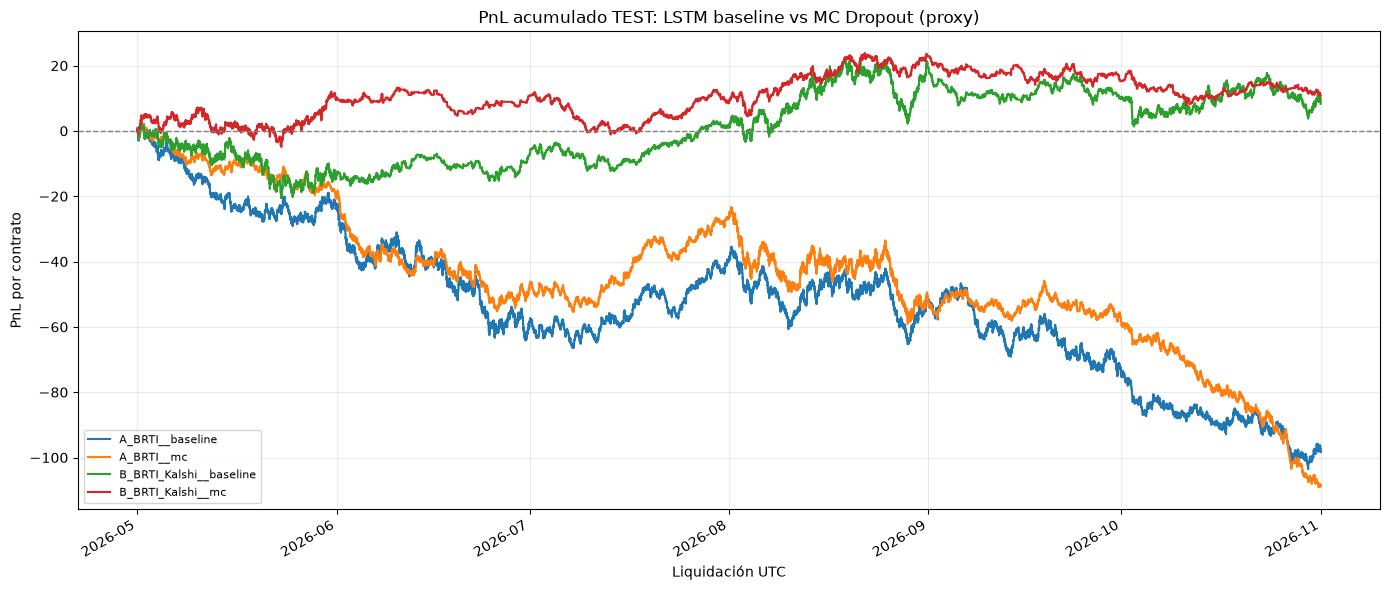

,model,fold,rows,contracts,logloss,weighted_logloss,brier,weighted_brier,auc
0,A_BRTI,2026-05,37478,2730,0.45064,0.44917,0.15035,0.14981,0.86415
1,A_BRTI__mc_mean,2026-05,37478,2730,0.45091,0.44946,0.15039,0.14985,0.86411
2,B_BRTI_Kalshi,2026-05,37478,2730,0.43983,0.43781,0.14611,0.14541,0.87235
3,B_BRTI_Kalshi__mc_mean,2026-05,37478,2730,0.44031,0.43831,0.14614,0.14543,0.87233
4,A_BRTI,2026-06,36293,2635,0.51024,0.51095,0.17198,0.17226,0.82077
5,A_BRTI__mc_mean,2026-06,36293,2635,0.51068,0.51140,0.17209,0.17238,0.82065
6,B_BRTI_Kalshi,2026-06,36293,2635,0.42930,0.42882,0.14188,0.14174,0.87900
7,B_BRTI_Kalshi__mc_mean,2026-06,36293,2635,0.42943,0.42897,0.14191,0.14177,0.87902
8,A_BRTI,2026-07,38127,2758,0.52064,0.52230,0.17609,0.17677,0.81283
9,A_BRTI__mc_mean,2026-07,38127,2758,0.52118,0.52283,0.17625,0.17693,0.81254


Nota: no se verificó ejecutabilidad histórica, tarifas reales ni calibración de intervalos MC.


In [8]:
if all_trades:
    trades=pd.concat(all_trades,ignore_index=True)
    trades=trades.sort_values(['strategy_id','exit_ts','ticker'],kind='stable').reset_index(drop=True)
    trades['pnl_acumulado']=trades.groupby('strategy_id').pnl_proxy.cumsum()
    trades['drawdown']=trades['pnl_acumulado']-trades.groupby('strategy_id').pnl_acumulado.cummax().clip(lower=0)
    trades.to_csv(OUT/'operaciones_test_walkforward.csv',index=False)
    summary=trades.groupby(['model','variant']).agg(
        operaciones=('ticker','size'),contratos=('ticker','nunique'),
        pnl_total=('pnl_proxy','sum'),pnl_por_operacion=('pnl_proxy','mean'),
        win_rate=('pnl_proxy',lambda x:(x>0).mean()),
        max_drawdown=('drawdown','min')).reset_index()
    summary.to_csv(OUT/'comparacion_estrategias.csv',index=False)
    display(summary.round(5))
    fig,ax=plt.subplots(figsize=(14,6))
    for strategy,g in trades.groupby('strategy_id'):
        ax.step(pd.to_datetime(g.exit_ts,unit='s',utc=True),
                g.pnl_acumulado,where='post',label=strategy)
    ax.axhline(0,color='gray',ls='--',lw=1)
    ax.set(title='PnL acumulado TEST: LSTM baseline vs MC Dropout (proxy)',
           xlabel='Liquidación UTC',ylabel='PnL por contrato')
    ax.grid(alpha=.25);ax.legend(fontsize=8)
    fig.autofmt_xdate();fig.tight_layout()
    fig.savefig(OUT/'pnl_comparativo.png',dpi=160);plt.show()
else:
    print('No hubo operaciones en TEST para las configuraciones seleccionadas.')
metrics=pd.DataFrame(all_metrics)
display(metrics.round(5))
print('Nota: no se verificó ejecutabilidad histórica, tarifas reales ni calibración de intervalos MC.')

## Modelo final para noviembre

El walk-forward anterior evalúa octubre con un modelo entrenado antes de octubre. Para usar los datos de octubre al predecir en noviembre, entreno **otro modelo final** con todos los contratos hasta el 31 de octubre.

Uso la arquitectura y la cantidad de épocas seleccionadas en el último fold (validación de septiembre). No vuelvo a elegir hiperparámetros usando el test de octubre. Guardo un modelo por conjunto de variables, su escalador y las políticas elegidas con la validación de septiembre. En noviembre se cargan estos archivos para predecir, sin entrenar de nuevo.

Los archivos `.pt` solo deben cargarse si fueron creados por nosotros o por una fuente confiable.


In [9]:
# Entrenamiento final: diciembre 2025 - octubre 2026 inclusive.
# Octubre se incorpora al entrenamiento; noviembre queda fuera.
FINAL_DIR = OUT / 'modelos_para_noviembre'
FINAL_DIR.mkdir(parents=True, exist_ok=True)
FINAL_CUTOFF = pd.Timestamp('2026-11-01', tz='UTC').timestamp()
final_data = base.loc[base.contract_close_ts < FINAL_CUTOFF].copy()
assert not final_data.empty
assert last_fold_models, 'No se guardaron configuraciones del fold de octubre.'
assert set(last_fold_models) == set(models_features)

for name, features in models_features.items():
    selected = last_fold_models[name]
    config = PARAM_GRID[selected['grid_id']]
    epochs = int(selected['epochs'])
    assert epochs >= 1
    scaler = StandardScaler().fit(final_data[features].to_numpy(dtype=np.float32))
    dataset = ContractSequenceDataset(final_data, features, scaler, SEQ_LEN)

    # Semilla fija para poder repetir el entrenamiento.
    seed = SEED + 10000 + selected['grid_id']
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if DEVICE.type == 'cuda':
        torch.cuda.manual_seed_all(seed)
    model = LSTMClassifier(
        n_features=len(features), projection_dim=16,
        hidden_dim=config['hidden_dim'], num_layers=config['num_layers'],
        dropout=config['dropout']
    ).to(DEVICE)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=config['lr'], weight_decay=config['weight_decay']
    )
    loss_fn = nn.CrossEntropyLoss(reduction='none')
    loader = DataLoader(
        dataset, batch_size=BATCH_SIZE, shuffle=True,
        generator=torch.Generator().manual_seed(seed)
    )

    for epoch in range(epochs):
        model.train()
        total_loss = 0.0
        for x, lengths, y, w in loader:
            optimizer.zero_grad(set_to_none=True)
            logits = model(x.to(DEVICE), lengths)
            losses = loss_fn(logits, y.long().to(DEVICE))
            weights = w.to(DEVICE)
            loss = (losses * weights).sum() / weights.sum()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            total_loss += float(loss.item())

    # Guardar solamente pesos y metadatos sencillos, no objetos Python serializados.
    checkpoint = {
        'model_state_dict': {k: v.detach().cpu() for k, v in model.state_dict().items()},
        'features': list(features),
        'scaler_mean': scaler.mean_.tolist(),
        'scaler_scale': scaler.scale_.tolist(),
        'scaler_var': scaler.var_.tolist(),
        'scaler_n_samples_seen': int(scaler.n_samples_seen_),
        'architecture': {
            'n_features': len(features), 'projection_dim': 16,
            'hidden_dim': config['hidden_dim'], 'num_layers': config['num_layers'],
            'dropout': config['dropout'], 'seq_len': SEQ_LEN
        },
        'training': {
            'trained_through_exclusive_utc': '2026-11-01T00:00:00Z',
            'rows': len(final_data), 'contracts': final_data.ticker.nunique(),
            'epochs': epochs, 'seed': seed,
            'hyperparameters': config,
            'selection': 'hiperparametros y epocas del fold octubre; validacion septiembre',
            'mc_samples': MC_SAMPLES,
            'mc_confidence_levels': MC_CONFIDENCE_LEVELS
        },
        'policies': selected['policies']
    }
    filename = FINAL_DIR / f'{name}_final_octubre.pt'
    torch.save(checkpoint, filename)
    print(name, '| épocas:', epochs, '| contratos:', final_data.ticker.nunique(),
          '| guardado:', filename)

print('Los modelos finales están listos para evaluar noviembre.')


A_BRTI | épocas: 14 | contratos: 28597 | guardado: data/modeling/walkforward_lstm_mc/modelos_para_noviembre/A_BRTI_final_octubre.pt
B_BRTI_Kalshi | épocas: 19 | contratos: 28597 | guardado: data/modeling/walkforward_lstm_mc/modelos_para_noviembre/B_BRTI_Kalshi_final_octubre.pt
Los modelos finales están listos para evaluar noviembre.


### Cómo cargar el modelo final

Esta celda comprueba que el archivo se puede reconstruir y permite reutilizarlo en noviembre. Para predecir, `nuevos_datos` debe tener las mismas columnas y el mismo procesamiento del notebook 02. No hay que incluir el resultado del contrato como feature; la clase de dataset actual sí requiere `target_yes`, por lo que para inferencia en vivo habrá que adaptar esa clase para no exigir etiquetas.

In [10]:
# Ejemplo: cargar el modelo B entrenado hasta octubre.
checkpoint_path = FINAL_DIR / 'B_BRTI_Kalshi_final_octubre.pt'
saved = torch.load(checkpoint_path, map_location='cpu', weights_only=True)
arch = saved['architecture']
loaded_model = LSTMClassifier(
    n_features=arch['n_features'],
    projection_dim=arch['projection_dim'],
    hidden_dim=arch['hidden_dim'],
    num_layers=arch['num_layers'],
    dropout=arch['dropout']
)
loaded_model.load_state_dict(saved['model_state_dict'])
loaded_model.eval()

loaded_scaler = StandardScaler()
loaded_scaler.mean_ = np.asarray(saved['scaler_mean'], dtype=np.float64)
loaded_scaler.scale_ = np.asarray(saved['scaler_scale'], dtype=np.float64)
loaded_scaler.var_ = np.asarray(saved['scaler_var'], dtype=np.float64)
loaded_scaler.n_features_in_ = len(saved['features'])
loaded_scaler.n_samples_seen_ = saved['scaler_n_samples_seen']
print('Modelo cargado:', checkpoint_path.name)
print('Features:', saved['features'])
print('Políticas:', saved['policies'])


Modelo cargado: B_BRTI_Kalshi_final_octubre.pt
Features: ['minutes_remaining', 'brti_distance_to_strike_pct', 'brti_return_1m', 'ewma_volatility_bps_min', 'kalshi_yes_price_proxy', 'kalshi_spread']
Políticas: {'baseline': {'strategy': 'baseline', 'confidence': None, 'min_edge': 0.01, 't_min': 5, 't_max': 10, 'validation_trades': 1256, 'validation_pnl': 18.52}, 'mc': {'strategy': 'mc', 'confidence': 0.8, 'min_edge': 0.01, 't_min': 1, 't_max': 14, 'validation_trades': 459, 'validation_pnl': 3.835999999999999}}
